# Rodent AI — FOMO Training (MobileNetV2 0.35) on Google Colab

Trains a **FOMO** model — same architecture as Edge Impulse:
- Input: **96×96 grayscale**
- Backbone: **MobileNetV2 α=0.35** (pretrained ImageNet, fine-tuned)
- Output: **12×12 grid** (stride 8), each cell predicts rat / background
- Export: **TFLite int8**

## Before running
1. `fomo_dataset.zip` must be uploaded to your **Google Drive**
   (built from **all** of `ei_curated`: 4192 train + 1040 test — `cur_` rats plus
   `bg_`/`neg_`/`tgt_` backgrounds).
2. Runtime → Change runtime type → **T4 GPU**.
3. Run all cells in order.

## 1. Install dependencies

In [9]:
!pip install -q tensorflow Pillow numpy
import tensorflow as tf
print('TF version:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TF version: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Mount Google Drive and unzip dataset

In [10]:
from google.colab import drive
drive.mount('/content/drive')

import os, zipfile

# ── EDIT this path if your zip is in a sub-folder ──────────────────────────
ZIP_PATH = '/content/drive/MyDrive/fomo_dataset.zip'
DEST     = '/content/fomo_dataset'
# ───────────────────────────────────────────────────────────────────────────

if not os.path.exists(DEST):
    print('Unzipping...')
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(DEST)
    print('Done.')
else:
    print('Already unzipped.')

# Quick sanity check
for split in ('training', 'testing'):
    imgs = [f for f in os.listdir(f'{DEST}/{split}') if f.endswith('.jpg')]
    print(f'{split}: {len(imgs)} images')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Already unzipped.
training: 4192 images
testing: 1040 images


## 3. Parse labels → FOMO 12×12 grid targets

Each image maps to a **12×12×1** float label. Each rat marks the cell its centroid falls in **plus a 1-cell border** (a 3×3 block, `LABEL_SPREAD`) — this *label spreading* gives the network up to ~9× more positive signal than a single cell, lifting recall and calibrating the scores. Background images are all zeros.


In [ ]:
import json
import numpy as np
from pathlib import Path
from PIL import Image

IMG_SIZE     = 96    # FOMO input (96×96 px)
GRID_SIZE    = 12    # 96 / stride(8) = 12
STRIDE       = IMG_SIZE // GRID_SIZE   # 8

# ── Target-building options ──────────────────────────────────────────────────
# USE_GAUSSIAN: paint each rat as a soft Gaussian peak (CenterNet-style) instead
#   of a hard 3×3 block. Soft targets localise better and calibrate the output
#   scores, which lifts the object-level F1. Set False to reproduce the exact
#   previous hard-label model.
# GAUSS_SIGMA:  width of that peak, in grid cells.
# LABEL_SPREAD: half-size of the hard block used when USE_GAUSSIAN=False (1 → 3×3).
USE_GAUSSIAN = True
GAUSS_SIGMA  = 0.8
LABEL_SPREAD = 1

# LETTERBOX: pad each image to a square BEFORE resizing so the ~6% of non-square
#   source images are not distorted (box coords are mapped with the same scale +
#   pad so labels stay aligned).
#   ⚠ KEEP FALSE unless you also letterbox the camera frame in the firmware —
#   otherwise training and the device preprocess differently (a mismatch that
#   HURTS accuracy). The current firmware squashes to 96×96, so training does too.
LETTERBOX = False


def prepare_image(im):
    """Grayscale PIL image → (arr[96,96,1] float32, scale|None, pad_x, pad_y).

    scale=None means legacy squash (independent x/y resize); a float means
    letterbox (uniform scale + centred black padding).
    """
    ow, oh = im.size
    if LETTERBOX:
        s = IMG_SIZE / max(ow, oh)
        nw, nh = max(1, int(round(ow * s))), max(1, int(round(oh * s)))
        canvas = Image.new('L', (IMG_SIZE, IMG_SIZE), 0)
        px, py = (IMG_SIZE - nw) // 2, (IMG_SIZE - nh) // 2
        canvas.paste(im.resize((nw, nh), Image.BILINEAR), (px, py))
        arr = np.array(canvas, dtype=np.float32) / 255.0
        return arr[..., np.newaxis], s, float(px), float(py)
    arr = np.array(im.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.float32) / 255.0
    return arr[..., np.newaxis], None, 0.0, 0.0


def _paint_gaussian(label, row, col, sigma=None):
    """Max-combine a Gaussian peak centred at grid cell (row, col) into label."""
    if sigma is None:
        sigma = GAUSS_SIGMA
    rad = int(np.ceil(3 * sigma))
    for r in range(max(0, row - rad), min(GRID_SIZE - 1, row + rad) + 1):
        for c in range(max(0, col - rad), min(GRID_SIZE - 1, col + rad) + 1):
            g = np.exp(-((r - row) ** 2 + (c - col) ** 2) / (2.0 * sigma * sigma))
            if g > label[r, c, 0]:
                label[r, c, 0] = g


def boxes_to_fomo_label(boxes_info, orig_w, orig_h, scale=None, pad_x=0.0, pad_y=0.0):
    """EI box list [{x,y,width,height}] → (12,12,1) float32 FOMO target grid.

    USE_GAUSSIAN=True  → each rat is a soft Gaussian peak (values in (0,1], max-
                         combined); the exact centroid cell is 1.0.
    USE_GAUSSIAN=False → each rat marks a (2*LABEL_SPREAD+1)² block of 1.0
                         (the previous behaviour).
    Coordinates honour the letterbox scale + pad when given, else legacy squash.
    """
    label = np.zeros((GRID_SIZE, GRID_SIZE, 1), dtype=np.float32)
    for b in boxes_info:
        cx = b['x'] + b['width']  / 2.0
        cy = b['y'] + b['height'] / 2.0
        if scale is not None:                       # letterbox: uniform scale + pad
            cx96, cy96 = cx * scale + pad_x, cy * scale + pad_y
        else:                                       # legacy squash: independent x/y
            cx96, cy96 = cx * IMG_SIZE / orig_w, cy * IMG_SIZE / orig_h
        col = int(min(max(cx96 // STRIDE, 0), GRID_SIZE - 1))
        row = int(min(max(cy96 // STRIDE, 0), GRID_SIZE - 1))
        if USE_GAUSSIAN:
            _paint_gaussian(label, row, col)
        else:
            r0, r1 = max(0, row - LABEL_SPREAD), min(GRID_SIZE - 1, row + LABEL_SPREAD)
            c0, c1 = max(0, col - LABEL_SPREAD), min(GRID_SIZE - 1, col + LABEL_SPREAD)
            label[r0:r1 + 1, c0:c1 + 1, 0] = 1.0
    return label


def load_split(split_dir):
    split_dir = Path(split_dir)
    data = json.loads((split_dir / 'bounding_boxes.labels').read_text())
    bb = data['boundingBoxes']
    images, labels = [], []
    skipped = 0
    for fname, boxes_info in bb.items():
        img_path = split_dir / fname
        if not img_path.exists():
            skipped += 1
            continue
        try:
            im = Image.open(img_path).convert('L')   # grayscale
            orig_w, orig_h = im.size
            arr, s, px, py = prepare_image(im)        # (96,96,1)
        except Exception:
            skipped += 1
            continue
        label = boxes_to_fomo_label(boxes_info, orig_w, orig_h, scale=s, pad_x=px, pad_y=py)
        images.append(arr)
        labels.append(label)
    if skipped:
        print(f'  [skipped {skipped} missing/corrupt files]')
    return np.array(images, dtype=np.float32), np.array(labels, dtype=np.float32)

print('Loading training set...')
X_train, Y_train = load_split(f'{DEST}/training')
print(f'  X={X_train.shape}  Y={Y_train.shape}')

print('Loading test set...')
X_test, Y_test = load_split(f'{DEST}/testing')
print(f'  X={X_test.shape}  Y={Y_test.shape}')

# A cell counts as "rat" if its target >= 0.5 (works for hard 1.0 blocks and
# Gaussian peaks alike — the exact centroid is always 1.0).
_tr_pos = (Y_train.max(axis=(1, 2, 3)) >= 0.5)
_te_pos = (Y_test.max(axis=(1, 2, 3)) >= 0.5)
print(f'\nTrain: {int(_tr_pos.sum())} positives (rat), {int((~_tr_pos).sum())} backgrounds')
print(f'Test:  {int(_te_pos.sum())} positives, {int((~_te_pos).sum())} backgrounds')
_mode = f'Gaussian(sigma={GAUSS_SIGMA})' if USE_GAUSSIAN else f'hard block(spread={LABEL_SPREAD})'
print(f'Targets: {_mode}, letterbox={LETTERBOX}')
print(f'Positive-cell mass (Y_train.mean): {Y_train.mean():.4f}  '
      f'(prior bias auto-adapts from this)')


Loading training set...
  X=(4192, 96, 96, 1)  Y=(4192, 12, 12, 1)
Loading test set...
  X=(1040, 96, 96, 1)  Y=(1040, 12, 12, 1)

Train: 3600 positives (rat), 592 backgrounds
Test:  900 positives, 140 backgrounds
Positive-cell fraction (LABEL_SPREAD=1): 0.0893 (~0.011 at single-cell)


## 4. Build FOMO model (MobileNetV2 α=0.35)

Exact same logic as Edge Impulse FOMO:
- MobileNetV2 truncated at `block_6_expand_relu` → **12×12×96** feature map (stride 8)
- Extra 1×1 Conv (32 ch, ReLU) + 1×1 Conv (1 ch, sigmoid) → **12×12×1** detection grid

In [12]:
import math
import tensorflow as tf
from tensorflow.keras import layers, Model

def build_fomo(input_shape=(96, 96, 1), alpha=0.35, pos_frac=0.05):
    inp = layers.Input(shape=input_shape, name='input_grayscale')

    # MobileNetV2 expects 3 channels — repeat the grayscale channel 3×.
    # Use a native Concatenate (NOT Lambda): Keras 3 can't infer a Lambda's
    # output shape here (raises NotImplementedError), and Lambda+tf.repeat is
    # also fragile for the int8 TFLite export later. Concatenate is both.
    x = layers.Concatenate(axis=-1, name='gray_to_rgb')([inp, inp, inp])

    # MobileNetV2's ImageNet weights were trained on inputs scaled to [-1, 1],
    # but our images arrive as [0, 1]. Without this remap the pretrained
    # features get the wrong range and barely activate — a second cause of the
    # collapse. Rescaling is a plain affine op, fully int8-TFLite safe.
    x = layers.Rescaling(scale=2.0, offset=-1.0, name='to_pm1')(x)  # [0,1] -> [-1,1]

    # MobileNetV2 0.35 backbone (ImageNet weights)
    base = tf.keras.applications.MobileNetV2(
        input_shape=(input_shape[0], input_shape[1], 3),
        alpha=alpha,
        include_top=False,
        weights='imagenet'
    )

    # Find stride-8 feature layer (block_6 → 12×12 for 96×96 input)
    target_layer = None
    for lyr in base.layers:
        if 'block_6_expand_relu' in lyr.name:
            target_layer = lyr.name
            break
    # Fallback: first layer whose spatial output is 12×12
    if target_layer is None:
        for lyr in base.layers:
            out = lyr.output
            if hasattr(out, 'shape') and len(out.shape) == 4 and out.shape[1] == 12:
                target_layer = lyr.name
                break
    print(f'Backbone truncated at: {target_layer}')

    backbone = Model(
        inputs=base.input,
        outputs=base.get_layer(target_layer).output,
        name='mobilenetv2_035'
    )
    print(f'Feature map shape: {backbone.output_shape}')

    x = backbone(x)                                     # (B, 12, 12, C)

    # FOMO head
    x = layers.Conv2D(32, 1, padding='same',
                      activation='relu',    name='head_conv')(x)
    # Prior-bias init (RetinaNet trick): start the sigmoid near the true rat-cell
    # frequency (pos_frac) instead of 50%, so the background gradient doesn't
    # swamp training and collapse the model to all-empty. pos_frac is measured
    # from the (spread) labels — see the build call below — so it auto-adapts to
    # whatever LABEL_SPREAD is set to.
    pos_frac = min(max(pos_frac, 1e-4), 0.5)
    output_bias = tf.keras.initializers.Constant(-math.log((1.0 - pos_frac) / pos_frac))
    x = layers.Conv2D(1,  1, padding='same',
                      activation='sigmoid', bias_initializer=output_bias,
                      name='fomo_output')(x)  # (B, 12, 12, 1)

    return Model(inputs=inp, outputs=x, name='FOMO_rat')

# Prior bias from the actual positive-cell fraction of the (spread) labels.
POS_FRAC = float(Y_train.mean())
print(f'Output prior set from positive-cell fraction: {POS_FRAC:.4f}')
model = build_fomo(pos_frac=POS_FRAC)
model.summary(line_length=80)


Output prior set from positive-cell fraction: 0.0893
Backbone truncated at: block_6_expand_relu
Feature map shape: (None, 12, 12, 96)


Model: "FOMO_rat"

┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)          ┃ Output Shape      ┃     Param # ┃ Connected to       ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│ input_grayscale       │ (None, 96, 96, 1) │           0 │ -                  │
│ (InputLayer)          │                   │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ gray_to_rgb           │ (None, 96, 96, 3) │           0 │ input_grayscale[0… │
│ (Concatenate)         │                   │             │ input_grayscale[0… │
│                       │                   │             │ input_grayscale[0… │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ to_pm1 (Rescaling)    │ (None, 96, 96, 3) │           0 │ gray_to_rgb[0][0]  │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ mobilenetv2_035       │ (None, 12, 12,    │      17,584 │ to_pm1[0][0]       │
│ (Functional)          │ 96)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ head_conv (Conv2D)    │ (None, 12, 12,    │       3,104 │ mobilenetv2_035[0… │
│                       │ 32)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ fomo_output (Conv2D)  │ (None, 12, 12, 1) │          33 │ head_conv[0][0]    │
└───────────────────────┴───────────────────┴─────────────┴────────────────────┘

 Total params: 20,721 (80.94 KB)

 Trainable params: 18,977 (74.13 KB)

 Non-trainable params: 1,744 (6.81 KB)

## 5. Loss function and compile

Binary **focal loss** (γ=2, α=0.5) handles the imbalance (~13 positive cells out of 144 per image after label spreading). α=0.5 (up from the RetinaNet default 0.25) up-weights the rat cells. The base LR is **3e-4** — lower than the usual 1e-3 because spreading made the loss ~5× larger, and 1e-3 caused an early `val_loss` spike.


In [ ]:
def binary_focal_loss(gamma=2.0, alpha=0.5):
    """Focal loss — suppresses easy negatives, focuses on hard positives.

    alpha weights POSITIVE (rat) cells; (1-alpha) weights background. Kept at 0.5
    so the background term doesn't dominate the gradient (that had collapsed the
    model to all-empty). Raise toward 0.75 if recall is still too low.

    This smooth form ALSO accepts soft targets (the Gaussian heatmaps): with
    pt = 1 - |y_true - y_pred| and a linear alpha blend it is *identical* to the
    classic hard-label focal loss when y_true is 0/1 — so flipping USE_GAUSSIAN
    on or off needs no other change and can't regress the old behaviour.
    """
    def loss(y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        pt = 1.0 - tf.abs(y_true - y_pred)                    # = y_pred if y_true=1, 1-y_pred if y_true=0
        at = alpha * y_true + (1.0 - alpha) * (1.0 - y_true)  # = alpha if y_true=1, 1-alpha if y_true=0
        return -tf.reduce_mean(at * tf.pow(1.0 - pt, gamma) * tf.math.log(pt))
    return loss

# LR kept at 3e-4 (Adam). Gaussian targets carry a bit LESS positive mass than
# the hard 3×3 blocks, so the focal-loss magnitude and its gradients are gentler,
# not larger — 3e-4 stays safe (the earlier val_loss spike came from the opposite:
# a mass INCREASE at 1e-3). ReduceLROnPlateau trims it further if needed.
model.compile(
    optimizer=tf.keras.optimizers.Adam(3e-4),
    loss=binary_focal_loss(gamma=2.0, alpha=0.5),
    metrics=['binary_accuracy']
)
print('Model compiled.')


Model compiled.


## 6. Train

In [14]:
EPOCHS    = 60
BATCH     = 32
SAVE_PATH = '/content/fomo_best.keras'

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        SAVE_PATH, save_best_only=True, monitor='val_loss', verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=20, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=7, min_lr=1e-6, verbose=1
    ),
]

history = model.fit(
    X_train, Y_train,
    validation_data=(X_test, Y_test),
    epochs=EPOCHS,
    batch_size=BATCH,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/60
129/131 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - binary_accuracy: 0.8965 - loss: 0.0480
Epoch 1: val_loss improved from None to 0.05183, saving model to /content/fomo_best.keras

Epoch 1: finished saving model to /content/fomo_best.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 34s 41ms/step - binary_accuracy: 0.9031 - loss: 0.0366 - val_binary_accuracy: 0.9102 - val_loss: 0.0518 - learning_rate: 3.0000e-04
Epoch 2/60
129/131 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - binary_accuracy: 0.9130 - loss: 0.0288
Epoch 2: val_loss did not improve from 0.05183
131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - binary_accuracy: 0.9148 - loss: 0.0282 - val_binary_accuracy: 0.9110 - val_loss: 0.0582 - learning_rate: 3.0000e-04
Epoch 3/60
126/131 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - binary_accuracy: 0.9207 - loss: 0.0261
Epoch 3: val_loss did not improve from 0.05183
131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - binary_accuracy: 0.9212 - loss: 0.0260 - val_binary_accuracy: 0.9124 - val_loss: 0.0549 - learning_rate: 3.000

## 7. Plot training curves

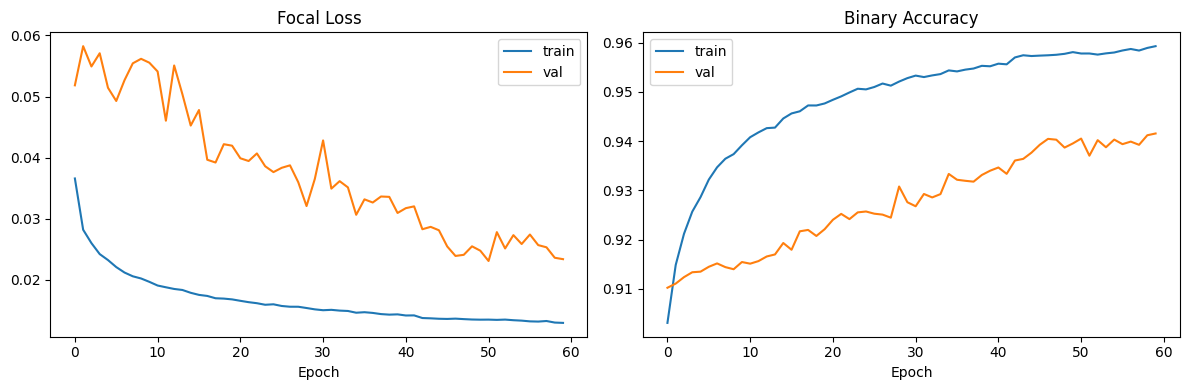

In [15]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history.history['loss'],     label='train')
ax1.plot(history.history['val_loss'], label='val')
ax1.set_title('Focal Loss')
ax1.set_xlabel('Epoch')
ax1.legend()

ax2.plot(history.history['binary_accuracy'],     label='train')
ax2.plot(history.history['val_binary_accuracy'], label='val')
ax2.set_title('Binary Accuracy')
ax2.set_xlabel('Epoch')
ax2.legend()

plt.tight_layout()
plt.savefig('/content/training_curves.png', dpi=120)
plt.show()

## 8. Evaluate — Precision / Recall / F1 on test set

In [ ]:
CONF_THRESHOLD = 0.3   # a PREDICTED cell is "rat" if score >= this
GT_POS_LEVEL   = 0.5   # a GROUND-TRUTH cell counts as rat if its target >= this
# GT_POS_LEVEL binarises the target so this eval works for BOTH the hard 1.0
# blocks and the soft Gaussian peaks (peak=1.0, skirt<0.5). Sweep the thresholds
# below to pick the best-F1 operating point for deployment.

preds    = model.predict(X_test, batch_size=32, verbose=0)   # (N, 12, 12, 1)
gt_bin   = (Y_test >= GT_POS_LEVEL).astype(np.float32)
pred_bin = (preds  >= CONF_THRESHOLD).astype(np.float32)

tp = int(np.sum((pred_bin == 1) & (gt_bin == 1)))
fp = int(np.sum((pred_bin == 1) & (gt_bin == 0)))
fn = int(np.sum((pred_bin == 0) & (gt_bin == 1)))

precision = tp / (tp + fp + 1e-8)
recall    = tp / (tp + fn + 1e-8)
f1        = 2 * precision * recall / (precision + recall + 1e-8)

print(f'Threshold : {CONF_THRESHOLD}')
print(f'TP={tp}  FP={fp}  FN={fn}')
print(f'Precision : {precision:.3f}')
print(f'Recall    : {recall:.3f}')
print(f'F1        : {f1:.3f}')

# Per-image false positive rate (images whose ground truth is background)
bg_mask = gt_bin.sum(axis=(1, 2, 3)) == 0
fp_images = int((pred_bin[bg_mask].sum(axis=(1, 2, 3)) > 0).sum())
print(f'\nFalse-positive images: {fp_images} / {int(bg_mask.sum())} backgrounds')

# --- Threshold sweep: find the best F1 without re-running the model ----------
print('\nthr    P      R      F1')
for thr in (0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7):
    pb = (preds >= thr).astype(np.float32)
    _tp = float(np.sum((pb == 1) & (gt_bin == 1)))
    _fp = float(np.sum((pb == 1) & (gt_bin == 0)))
    _fn = float(np.sum((pb == 0) & (gt_bin == 1)))
    _p = _tp / (_tp + _fp + 1e-8)
    _r = _tp / (_tp + _fn + 1e-8)
    _f = 2 * _p * _r / (_p + _r + 1e-8)
    print(f'{thr:.1f}  {_p:.3f}  {_r:.3f}  {_f:.3f}')


Threshold : 0.3
TP=10579  FP=12227  FN=2871
Precision : 0.464
Recall    : 0.787
F1        : 0.584

False-positive images: 111 / 140 backgrounds

thr    P      R      F1
0.1  0.234  0.969  0.376
0.2  0.348  0.898  0.501
0.3  0.464  0.787  0.584
0.4  0.616  0.641  0.629
0.5  0.770  0.481  0.592
0.6  0.878  0.346  0.497
0.7  0.942  0.243  0.386


In [17]:
# ── Object-level (per-rat) evaluation ────────────────────────────────────────
# Cell-level P/R/F1 is pessimistic — it penalises every off-by-one-cell hit and
# rewards the spread blob. What actually matters on-device is "did we find each
# rat?". Here we threshold the heatmap, take the CENTROID of each predicted blob
# as one detection, and match detections to ground-truth rat centroids within a
# tolerance. This is the number that reflects real deployment performance.
from scipy import ndimage

MATCH_DIST = 1.5   # cells; a detection within this of a GT centroid = a hit

try:
    preds
except NameError:
    preds = model.predict(X_test, batch_size=32, verbose=0)

def blob_centroids(grid_2d, thr):
    mask = grid_2d >= thr
    lbl, n = ndimage.label(mask)
    if n == 0:
        return []
    return ndimage.center_of_mass(mask, lbl, range(1, n + 1))  # [(row,col), ...]

def object_prf(preds, Y, thr, match_dist=MATCH_DIST):
    TP = FP = FN = 0
    for i in range(len(preds)):
        gt = blob_centroids(Y[i, :, :, 0], 0.5)      # GT blobs (labels are 0/1)
        pr = blob_centroids(preds[i, :, :, 0], thr)
        used = [False] * len(gt)
        for (pr_r, pr_c) in pr:
            best, best_d = -1, 1e9
            for j, (g_r, g_c) in enumerate(gt):
                if used[j]:
                    continue
                dd = ((pr_r - g_r) ** 2 + (pr_c - g_c) ** 2) ** 0.5
                if dd < best_d:
                    best, best_d = j, dd
            if best >= 0 and best_d <= match_dist:
                used[best] = True
                TP += 1
            else:
                FP += 1
        FN += used.count(False)
    P = TP / (TP + FP + 1e-9)
    R = TP / (TP + FN + 1e-9)
    F = 2 * P * R / (P + R + 1e-9)
    return TP, FP, FN, P, R, F

print('Per-OBJECT detection (predicted blob centroid ↔ GT rat centroid, tol=1.5 cells)')
print('thr     TP    FP    FN      P      R      F1')
best_thr, best_f1 = 0.0, 0.0
for thr in (0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7):
    TP, FP, FN, P, R, F = object_prf(preds, Y_test, thr)
    print(f'{thr:.1f}   {TP:5} {FP:5} {FN:5}   {P:.3f}  {R:.3f}  {F:.3f}')
    if F > best_f1:
        best_thr, best_f1 = thr, F
print(f'\nBest object-level F1 = {best_f1:.3f} at threshold {best_thr}')


Per-OBJECT detection (predicted blob centroid ↔ GT rat centroid, tol=1.5 cells)
thr     TP    FP    FN      P      R      F1
0.1     580  2592   860   0.183  0.403  0.252
0.2     806  1500   634   0.350  0.560  0.430
0.3    1027  1281   413   0.445  0.713  0.548
0.4    1163  1082   277   0.518  0.808  0.631
0.5    1125   714   315   0.612  0.781  0.686
0.6     941   310   499   0.752  0.653  0.699
0.7     753   123   687   0.860  0.523  0.650

Best object-level F1 = 0.699 at threshold 0.6


## 9. Export TFLite int8

Quantises weights **and** activations to int8 using 100 representative training images for calibration.

In [18]:
# Restore best weights
model.load_weights(SAVE_PATH)

# Representative dataset for int8 calibration
def representative_dataset():
    indices = np.random.choice(len(X_train), size=min(100, len(X_train)), replace=False)
    for i in indices:
        yield [X_train[i:i+1]]

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations         = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type  = tf.int8
converter.inference_output_type = tf.int8

tflite_model = converter.convert()

TFLITE_PATH = '/content/fomo_rat_int8.tflite'
with open(TFLITE_PATH, 'wb') as f:
    f.write(tflite_model)

print(f'TFLite int8: {TFLITE_PATH}  ({len(tflite_model)//1024} KB)')

Saved artifact at '/tmp/tmpzj3t3dmp'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 96, 96, 1), dtype=tf.float32, name='input_grayscale')
Output Type:
  TensorSpec(shape=(None, 12, 12, 1), dtype=tf.float32, name=None)
Captures:
  133871271615696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133871271620688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133868762703504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133871141195984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133871271616848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133868762703312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133868762701392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133868762704080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133868762703696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133868762706000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13386

/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


TFLite int8: /content/fomo_rat_int8.tflite  (57 KB)


## 10. Save to Google Drive + download

In [19]:
import shutil
from pathlib import Path
from google.colab import files

drive_out = Path('/content/drive/MyDrive/rodent_fomo_model')
drive_out.mkdir(exist_ok=True)

shutil.copy(SAVE_PATH,                     drive_out / 'fomo_best.keras')
shutil.copy(TFLITE_PATH,                   drive_out / 'fomo_rat_int8.tflite')
shutil.copy('/content/training_curves.png', drive_out / 'training_curves.png')

print('Saved to Drive:', drive_out)

# Direct download to your computer
files.download(TFLITE_PATH)

Saved to Drive: /content/drive/MyDrive/rodent_fomo_model


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes on ESP32-CAM deployment

The exported `fomo_rat_int8.tflite` is a **custom model** (not EI-wrapped).

### Option A — Re-import into Edge Impulse *(easiest, no firmware change)*
Upload the `.tflite` via *Deployment → Bring Your Own Model* (Enterprise plan).
EI wraps it into an Arduino library → same `rodent_webserver.ino` firmware, unchanged.

### Option B — TFLite Micro directly *(no EI required)*
Replace the EI SDK with the ESP32 TFLite Micro library.
Parse the output tensor yourself (12×12×1 float after dequantisation).
Ask your assistant to generate the updated firmware once you have the `.tflite`.

---

### How the FOMO output maps to detections
- Output tensor: **12×12×1** (int8, dequantise with scale+zero_point from tensor metadata)
- For each cell `(row, col)` with score ≥ threshold: rat centroid = `(col*8+4, row*8+4)` pixels in 96×96 space
- Scale back to original frame if needed